**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: ALEJANDRA EDITH TOBIAS VILLA
*   MATRÍCULA: A01840886

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [389]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

7 columnas numéricas, 8 columnas de texto

* Determina la cantidad de valores únicos por columna.

In [390]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [391]:
import os
DIR = "/content/drive/MyDrive/Colab Notebooks/MNA/TC5053 - Ciencia y analítica de datos/Actividad5Preprocesamiento"
os.chdir(DIR)

In [392]:
cardio_df = pd.read_csv('heart_disease.csv',index_col='id')
cardio_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB


In [393]:
#Determina la cantidad de valores únicos por columna.
cardio_df.nunique()

,0
age,50
sex,2
origin,4
cp,4
trestbps,60
chol,216
fbs,2
restecg,3
thalch,119
exang,2


2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [394]:
cardio_df.head()

,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
id,,,,,,,,,,,,,,,
1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [395]:
cardio_df['sex'] = cardio_df['sex'].astype('category') #Nominal
cardio_df['cp'] = cardio_df['cp'].astype('category') #Nominal
cardio_df['fbs'] = cardio_df['fbs'].astype('category') #Nominal
cardio_df['restecg'] = cardio_df['restecg'].astype('category') #Nominal
cardio_df['exang'] = cardio_df['exang'].astype('category') #Nominal
cardio_df['slope'] = cardio_df['slope'].astype('category') #Nominal
cardio_df['thal'] = cardio_df['thal'].astype('category') #Nominal
cardio_df['num'] = pd.Categorical(
    cardio_df['num'],
    categories=[0, 1, 2, 3, 4],
    ordered=True
) #Ordinaria
cardio_df['origin'] = cardio_df['origin'].astype('category') #Nominal


In [396]:
cardio_df.dtypes

,0
age,int64
sex,category
origin,category
cp,category
trestbps,float64
chol,float64
fbs,category
restecg,category
thalch,float64
exang,category


3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [397]:
#Variables Numéricas
num_cols = cardio_df.select_dtypes(include='number').columns

desc = cardio_df[num_cols].describe()
skew = cardio_df[num_cols].skew().to_frame().T.rename(index={0: 'skew'})
kurt = cardio_df[num_cols].kurt().to_frame().T.rename(index={0: 'kurt'})

stats = pd.concat([desc, skew, kurt])

display(stats)

,age,trestbps,chol,thalch,oldpeak,ca
count,918.000000,859.000000,888.000000,863.000000,856.000000,309.000000
mean,53.530501,132.294529,242.189189,137.528389,0.880607,0.676375
std,9.412783,18.535875,53.424806,25.950226,1.091840,0.935653
min,28.000000,80.000000,85.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,216.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000
75%,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000
skew,-0.193710,0.630411,1.640672,-0.209319,1.037990,1.165978
kurt,-0.382511,0.632992,6.573848,-0.483939,1.119834,0.199498


In [398]:
#Variables Categóricas
cat_cols = cardio_df.select_dtypes(include='category').columns

cardio_df[cat_cols].describe()

,sex,origin,cp,fbs,restecg,exang,slope,thal,num
count,918,918,918,829,918,863,610,434,918
unique,2,4,4,2,3,2,3,3,5
top,Male,Cleveland,asymptomatic,False,normal,False,flat,normal,0
freq,724,304,495,691,551,526,345,196,411


In [399]:
for col in cat_cols:
    print(f'\nFrecuencia de {col}:')
    display(cardio_df[col].value_counts(dropna=False).to_frame('Frecuencia'))


Frecuencia de sex:


,Frecuencia
sex,
Male,724
Female,194



Frecuencia de origin:


,Frecuencia
origin,
Cleveland,304
Hungary,292
VA Long Beach,200
Switzerland,122



Frecuencia de cp:


...

,Frecuencia
slope,
flat,345
NaN,308
upsloping,202
downsloping,63



Frecuencia de thal:


,Frecuencia
thal,
NaN,484
normal,196
reversable defect,192
fixed defect,46



Frecuencia de num:


,Frecuencia
num,
0,411
1,263
2,109
3,107
4,28


4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [400]:
#Calcula el porcentaje de valores faltantes en cada columna.
missing = (cardio_df.isnull().mean() * 100).round(2).to_frame(name='Porcentaje').sort_values(by='Porcentaje', ascending=False)

display(missing)

,Porcentaje
ca,66.34
thal,52.72
slope,33.55
fbs,9.69
oldpeak,6.75
trestbps,6.43
thalch,5.99
exang,5.99
chol,3.27
sex,0.00


In [401]:
#Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
cols_to_drop = missing[missing['Porcentaje'] > 30].index

cardio_df = cardio_df.drop(columns=cols_to_drop)

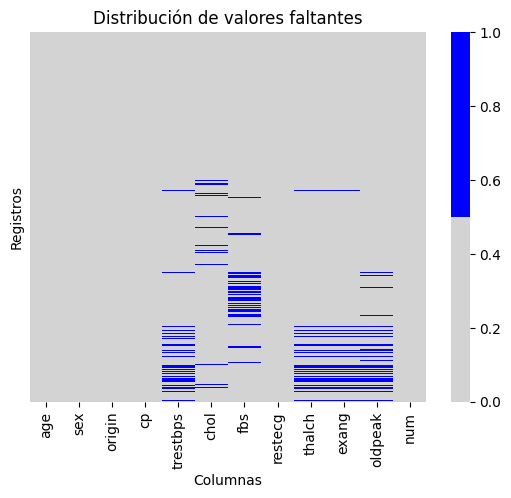

In [402]:
sns.heatmap(
    cardio_df.isnull(),
    cbar=True,
    yticklabels=False,
    cmap=['lightgray', 'blue']
)

plt.title('Distribución de valores faltantes')
plt.xlabel('Columnas')
plt.ylabel('Registros')
plt.show()

Las variables que cuentan con valores faltantes de manera simultanea son trestbps, thalch, exang, oldpeak. Sin embargo, la variable oldpeak no coincide en todos los casos.

No se puede determinar una razón clínica a este punto, pero coincide que trestbps es relacionado a presión arterial en reposo y los otros son respuesta cardiaca al ejercicio, por lo que una hipótesis es que hay un grupo de pacientes a la que no fue necesaria realizarles ese estudio o que no se pudo ya sea por algo médico o alguna otra cuestión. Se requiere ver su relación con otras variables para entenderlo mejor.

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [403]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {:.10f}'.format(p_value))

In [404]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {:.10f}'.format(p_value))

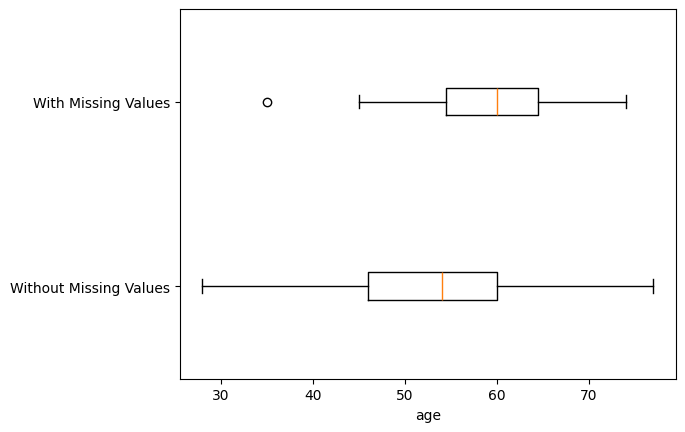

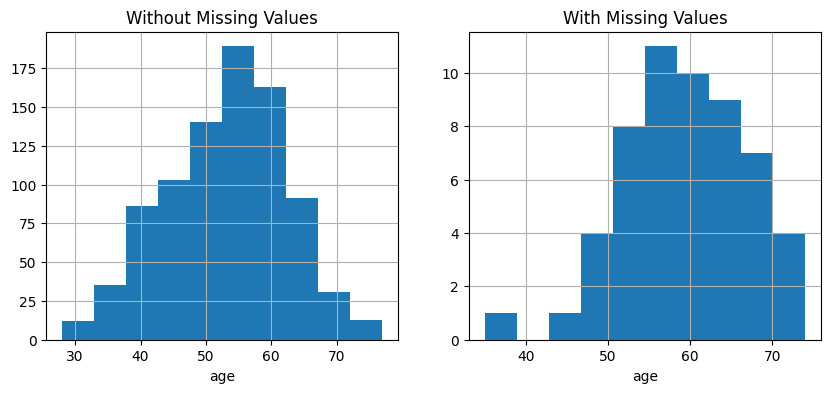

p-value of t-test: 0.0000015041


In [405]:
#Variable que identifique los valores faltantes en thalch.
BM_MV = cardio_df['thalch'].isnull()

#Comparar con age
Diagnose_MV_Numerical(cardio_df, 'age', BM_MV)

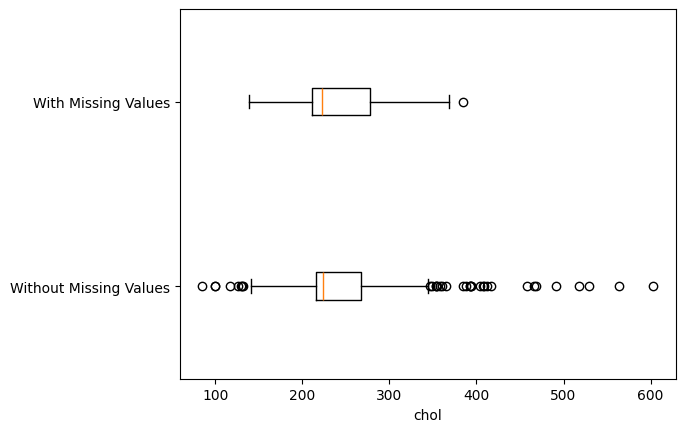

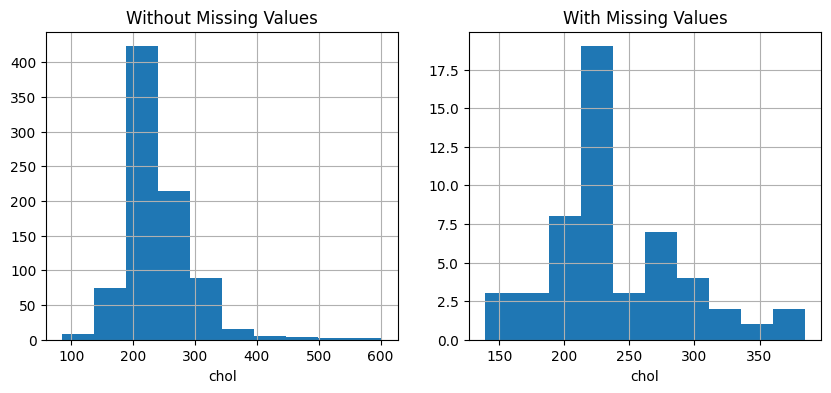

p-value of t-test: 0.7165289974


In [406]:
#Comparar con chol
Diagnose_MV_Numerical(cardio_df, 'chol', BM_MV)

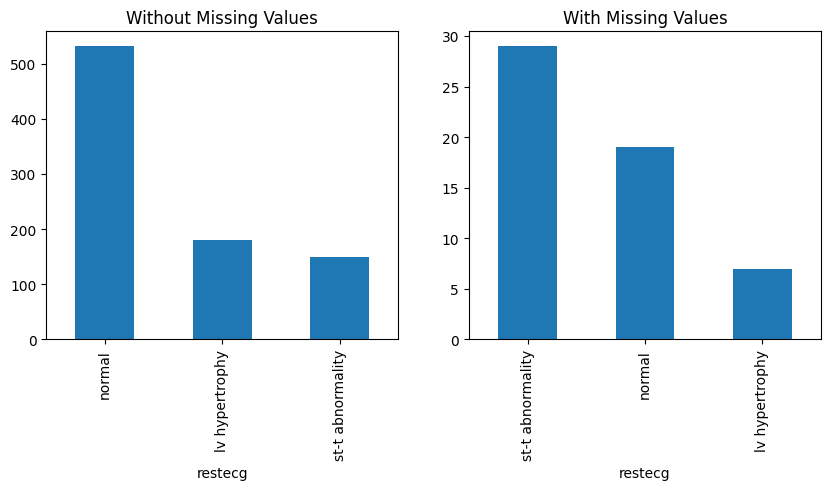

p-value of Chi_squared test: 0.0000000011


In [407]:
Diagnose_MV_Categorical(cardio_df, 'restecg', BM_MV)

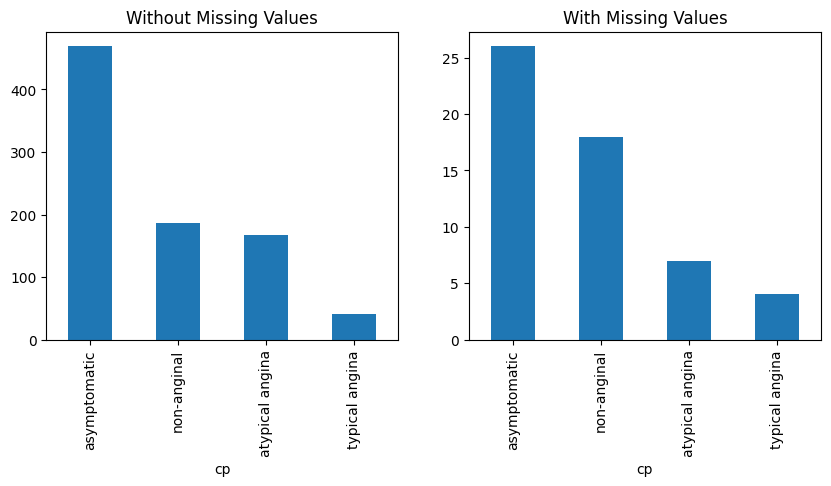

p-value of Chi_squared test: 0.1542009718


In [408]:
Diagnose_MV_Categorical(cardio_df, 'cp', BM_MV)

**Conclusión**

Con base en estos resultados, se encontró evidencia estadística de que los valores faltantes de la columna `thalch` están relacionados con las variables numéricas `age` y categórica `restecg`, ya que ambas pruebas mostraron diferencias estadísticamente significativas, con p-values menores a 0.05.

Por otro lado, no se encontró evidencia estadística suficiente para afirmar que los valores faltantes de `thalch` estén relacionados con las variables `chol` y `cp`, debido a que sus p-values fueron mayores a 0.05. Finalmente, estos resultados sugieren que el mecanismo de valores faltantes es MAR (*Missing At Random*), ya que se identificaron asociaciones con variables observadas.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

In [409]:
# Crear una copia de los datos originales
cardio_df_original = cardio_df.copy()

# Variables que se imputarán con la mediana
cols_median = ['thalch', 'trestbps', 'oldpeak']

# Imputar con la mediana de cada grupo de restecg
for col in cols_median:
    cardio_df[col] = cardio_df.groupby('restecg')[col].transform(
        lambda x: x.fillna(x.median())
    )

# Imputar exang con la moda de cada grupo de restecg
cardio_df['exang'] = cardio_df.groupby('restecg')['exang'].transform(
    lambda x: x.fillna(
        x.mode().iloc[0] if not x.mode().empty else float('nan')
    )
)

/tmp/ipykernel_2149/3761708284.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cardio_df[col] = cardio_df.groupby('restecg')[col].transform(
/tmp/ipykernel_2149/3761708284.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cardio_df['exang'] = cardio_df.groupby('restecg')['exang'].transform(


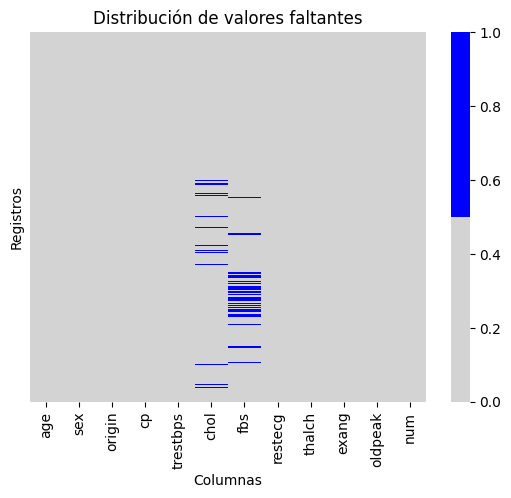

In [410]:
sns.heatmap(
    cardio_df.isnull(),
    cbar=True,
    yticklabels=False,
    cmap=['lightgray', 'blue']
)

plt.title('Distribución de valores faltantes')
plt.xlabel('Columnas')
plt.ylabel('Registros')
plt.show()

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


count    888.000000
mean     242.189189
std       53.424806
min       85.000000
25%      216.000000
50%      223.000000
75%      268.000000
max      603.000000
Name: chol, dtype: float64
Asimetría: 1.6406720078938555


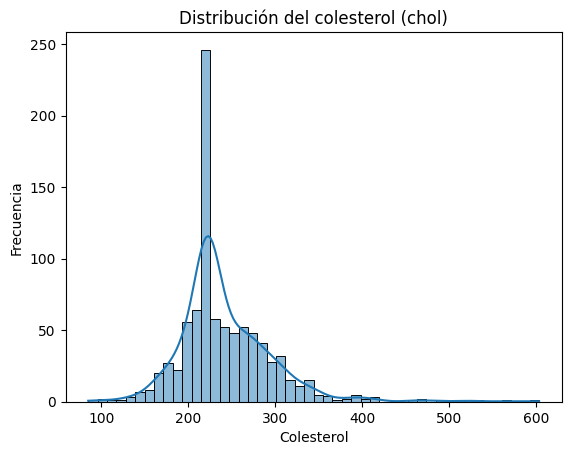

In [411]:
#Revisar primero las estadísticas de la columna col numérica para saber cómo es su distribución.

# Estadísticas descriptivas
print(cardio_df['chol'].describe())
print('Asimetría:', cardio_df['chol'].skew())

# Histograma
sns.histplot(data=cardio_df, x='chol', kde=True)
plt.title('Distribución del colesterol (chol)')
plt.xlabel('Colesterol')
plt.ylabel('Frecuencia')
plt.show()

In [412]:
# Imputar chol con la mediana
imputer_chol = SimpleImputer(strategy='median')
cardio_df[['chol']] = imputer_chol.fit_transform(cardio_df[['chol']])

# Imputar fbs con la moda
imputer_fbs = SimpleImputer(strategy='most_frequent')
cardio_df[['fbs']] = imputer_fbs.fit_transform(cardio_df[['fbs']])
cardio_df['fbs'] = cardio_df['fbs'].astype('category') #Se debe regresar a categórica

In [413]:
cardio_df.isnull().sum()

,0
age,0
sex,0
origin,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalch,0
exang,0


Para la estrategia de imputación, se utilizó la mediana para la columna `chol`, debido a que presenta una asimetría positiva. La mediana es menos sensible a los valores extremos que la media, por lo que resulta más adecuada para una distribución sesgada.

Para la columna `fbs` se utilizó la moda, debido a que representa una variable categórica binaria. Esta estrategia permite reemplazar los valores faltantes con la categoría que aparece con mayor frecuencia.

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

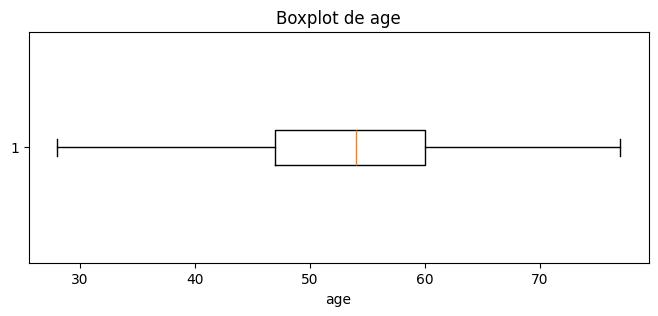

Outliers de age:
[]


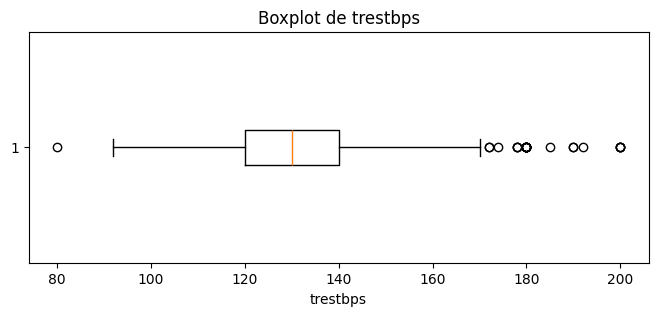

Outliers de trestbps:
[ 80. 172. 180. 200. 174. 178. 192. 180. 178. 180. 190. 180. 180. 180.
 180. 200. 180. 180. 180. 200. 185. 200. 180. 178. 172. 180. 190.]


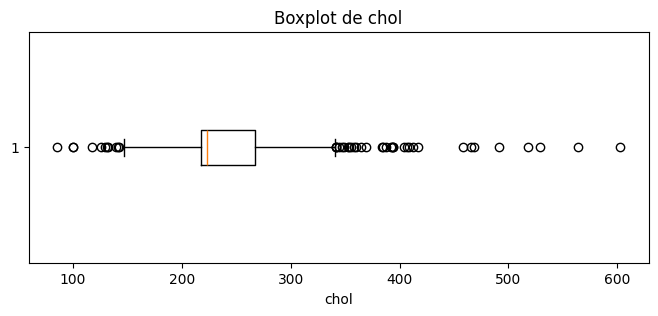

Outliers de chol:
[141. 126. 131. 132. 129. 100.  85. 117. 100. 142. 139. 354. 353. 417.
 360. 407. 564. 394. 409. 342. 358. 412. 468. 365. 344. 394. 347. 466.
 529. 392. 355. 603. 342. 404. 518. 388. 491. 342. 393. 458. 384. 349.
 369. 385.]


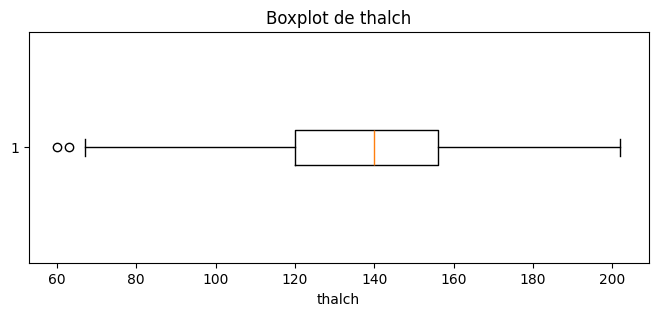

Outliers de thalch:
[60. 63.]


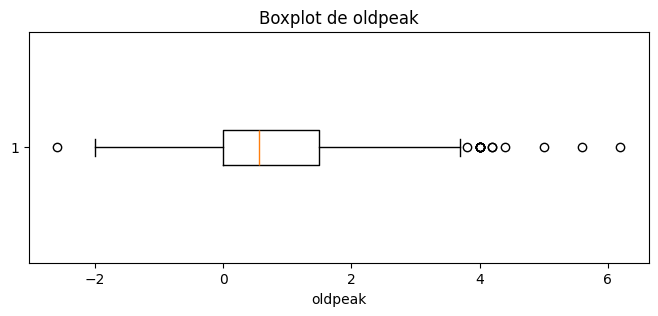

Outliers de oldpeak:
[-2.6  6.2  4.   5.6  4.   4.2  4.2  3.8  4.4  4.   4.   5.   4.   4.
  4.   4. ]


In [414]:
# Seleccionar las variables numéricas
num_cols = cardio_df.select_dtypes(include='number').columns

outliers = {}

for col in num_cols:
    plt.figure(figsize=(8, 3))

    boxplot = plt.boxplot(cardio_df[col].dropna(), vert=False)

    plt.title(f'Boxplot de {col}')
    plt.xlabel(col)
    plt.show()

    outliers[col] = boxplot['fliers'][0].get_xdata()

    print(f'Outliers de {col}:')
    print(outliers[col])

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior. Si coinciden.

In [415]:

# Calcular los cuartiles
Q1 = cardio_df['trestbps'].quantile(0.25)
Q3 = cardio_df['trestbps'].quantile(0.75)

# Calcular el rango intercuartílico
IQR = Q3 - Q1

# Calcular los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Obtener los valores atípicos
outliers_trestbps = cardio_df.loc[
    (cardio_df['trestbps'] < limite_inferior) |
    (cardio_df['trestbps'] > limite_superior),
    'trestbps'
]

print(outliers_trestbps.sort_values().to_numpy())


[ 80. 172. 172. 174. 178. 178. 178. 180. 180. 180. 180. 180. 180. 180.
 180. 180. 180. 180. 180. 185. 190. 190. 192. 200. 200. 200. 200.]


In [416]:
outliers_boxplot = outliers['trestbps']

print('¿Coinciden los resultados?')
print(set(outliers_trestbps) == set(outliers_boxplot))


¿Coinciden los resultados?
True


10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

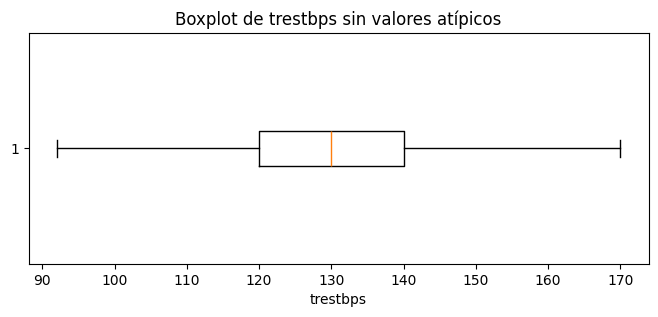

In [417]:
# Eliminar las filas que contienen esos valores atípicos
cardio_df = cardio_df[
    ~cardio_df['trestbps'].isin(outliers['trestbps'])
].copy()

# Dibujar el boxplot final
plt.figure(figsize=(8, 3))
plt.boxplot(cardio_df['trestbps'].dropna(), vert=False)
plt.title('Boxplot de trestbps sin valores atípicos')
plt.xlabel('trestbps')
plt.show()

---

**Declaración de uso de IA**

*   OpenAI. (2026). *ChatGPT (basado en GPT-6)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/

---